In [9]:
!pip install skorch imbalanced-learn -q

import os, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("On travaille sur :", device)

os.makedirs("/kaggle/working/images2", exist_ok=True)
IMG = "/kaggle/working/images2/"

DATA = "/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification"
print(os.listdir(DATA))

On travaille sur : cpu
['predictive_maintenance.csv']


In [10]:
df = pd.read_csv(f"{DATA}/predictive_maintenance.csv")
display(df.head())

print("Dimensions :", df.shape)
df.info()
print(df.describe().T)
print("\nValeurs manquantes :\n", df.isnull().sum())
print("Doublons (lignes) :", df.duplicated().sum())
print("Doublons Product ID :", df["Product ID"].duplicated().sum())
print("\n", df["Failure Type"].value_counts())

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


Dimensions : (10000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
                           count        mean          std     min      25%  \
UDI                      10000.0  5000.50000  2886.895680     1.0  2500.75   

Le dataset contient **10 000 lignes** et 10 colonnes : un identifiant (`UDI`, `Product ID`), le type de machine (`Type` : L, M ou H), cinq mesures (températures de l'air et du process, vitesse de rotation, couple, usure de l'outil), la colonne binaire `Target` et la colonne `Failure Type`, qui est la **classe à prédire** (problème multiclasse). Il n'y a **aucune valeur manquante** et **aucun doublon**.

La distribution de `Failure Type` est **très déséquilibrée** : « No Failure » représente 9 652 lignes (**96,5 %**), alors que les pannes n'ont que 112 (Heat Dissipation), 95 (Power), 78 (Overstrain), 45 (Tool Wear) et 18 (Random Failures) exemples. Un modèle qui répondrait toujours « No Failure » aurait donc 96,5 % d'accuracy sans rien détecter, ce qui impose de suivre le F1 macro et la sensibilité par classe, et de rééquilibrer les données d'entraînement.

In [11]:
# noms de colonnes plus simples
data = df.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rot_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Failure Type": "failure_type"})

# lignes incohérentes entre Target et failure_type
a = data[(data["Target"] == 1) & (data["failure_type"] == "No Failure")]
b = data[(data["Target"] == 0) & (data["failure_type"] != "No Failure")]
print("Target=1 mais 'No Failure' :", len(a))
print("Target=0 mais panne déclarée :", len(b))
print(b["failure_type"].value_counts())

# on retire ces lignes ambiguës
data = data.drop(index=a.index.union(b.index))

# colonnes inutiles : identifiants + Target (fuite d'information)
data = data.drop(columns=["UDI", "Product ID", "Target"])

print("\nNouvelle taille :", data.shape)
print(data["failure_type"].value_counts())

Target=1 mais 'No Failure' : 9
Target=0 mais panne déclarée : 18
failure_type
Random Failures    18
Name: count, dtype: int64

Nouvelle taille : (9973, 7)
failure_type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64


In [12]:
# Type : L < M < H (qualité croissante) -> encodage ordinal
data["Type"] = data["Type"].map({"L": 0, "M": 1, "H": 2})

# classe cible -> entiers
le = LabelEncoder()
data["label"] = le.fit_transform(data["failure_type"])
classes = le.classes_
n_classes = len(classes)
print(dict(enumerate(classes)))

{0: 'Heat Dissipation Failure', 1: 'No Failure', 2: 'Overstrain Failure', 3: 'Power Failure', 4: 'Tool Wear Failure'}


In [13]:
features = ["Type", "air_temp", "process_temp", "rot_speed", "torque", "tool_wear"]
X = data[features].values
y = data["label"].values

# stratify=y : chaque classe garde la même proportion dans train et test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# StandardScaler ajusté sur le train seulement
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype("float32")
X_test_s = scaler.transform(X_test).astype("float32")

print("Train :", X_train_s.shape, "| Test :", X_test_s.shape)
print("Moyennes train après scaling :", X_train_s.mean(0).round(2))

Train : (7978, 6) | Test : (1995, 6)
Moyennes train après scaling : [ 0. -0.  0.  0.  0.  0.]


J'ai séparé mes données en deux parties : 80 % pour entraîner le modèle (7 978 lignes) et 20 % pour le tester (1 995 lignes). J'ai utilisé `stratify=y` pour que les classes rares, comme Tool Wear qui n'a que 45 exemples, soient présentes dans les mêmes proportions dans le train et dans le test.

Ensuite, j'ai standardisé les variables avec `StandardScaler`. Je l'ai ajusté uniquement sur le train, puis appliqué au test, pour que le modèle ne "voie" aucune information du test pendant l'entraînement. Le résultat est correct : les moyennes du train sont bien à 0, donc la vitesse de rotation, les températures et le couple sont maintenant sur la même échelle.


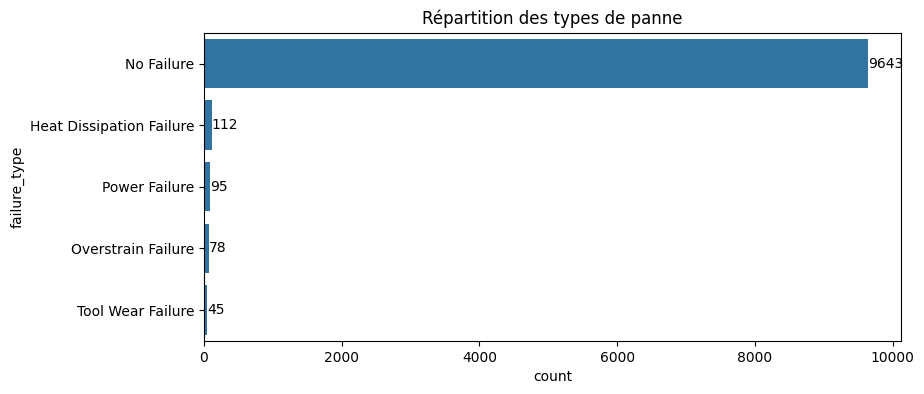

failure_type
No Failure                  96.69
Heat Dissipation Failure     1.12
Power Failure                0.95
Overstrain Failure           0.78
Tool Wear Failure            0.45
Name: proportion, dtype: float64


In [14]:
plt.figure(figsize=(9, 4))
ordre = data["failure_type"].value_counts().index
ax = sns.countplot(y="failure_type", data=data, order=ordre)
ax.bar_label(ax.containers[0])
plt.title("Répartition des types de panne")
plt.savefig(IMG + "eda_classes.png", dpi=150, bbox_inches="tight")
plt.show()

print((data["failure_type"].value_counts(normalize=True) * 100).round(2))

Le dataset est fortement déséquilibré : « No Failure » représente environ [97] % des données, alors que les classes de panne en ont chacune entre [45] et [112] exemples. Un modèle qui prédirait toujours « No Failure » aurait donc une très bonne accuracy sans rien détecter : il faudra suivre le F1 macro et la sensibilité par classe, et rééquilibrer le train.

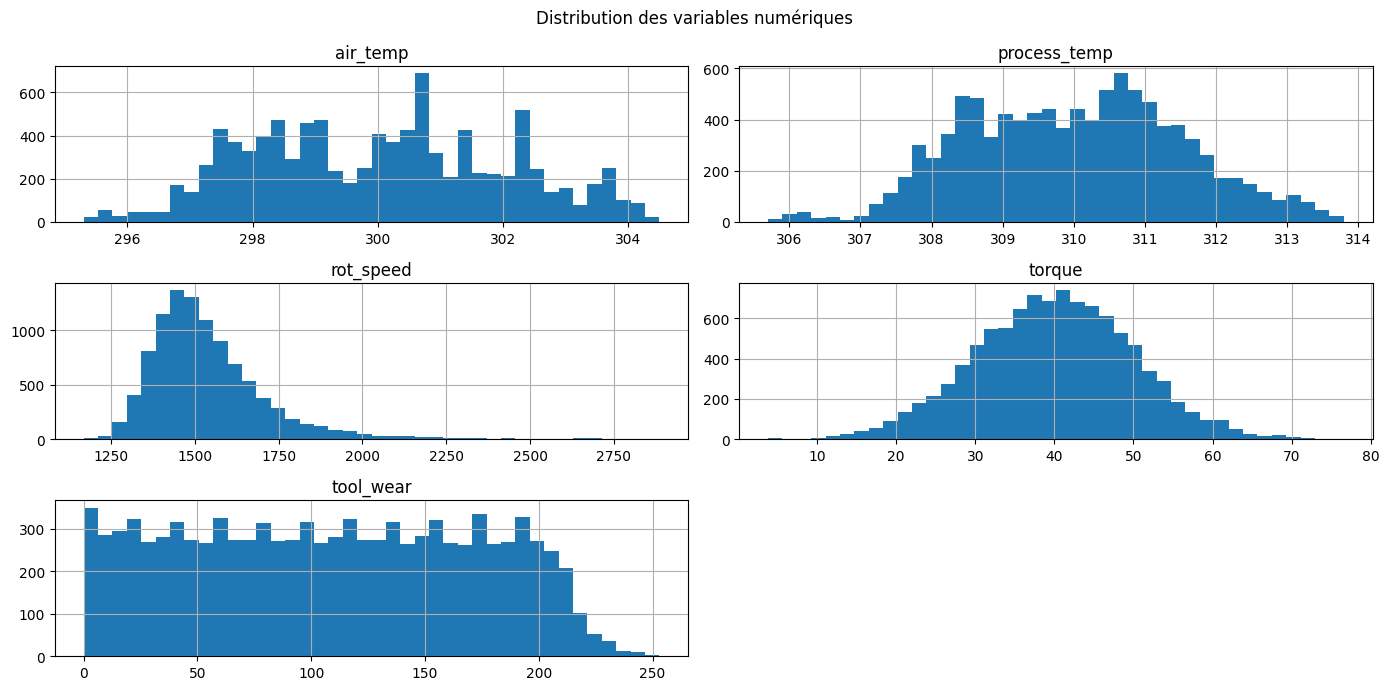

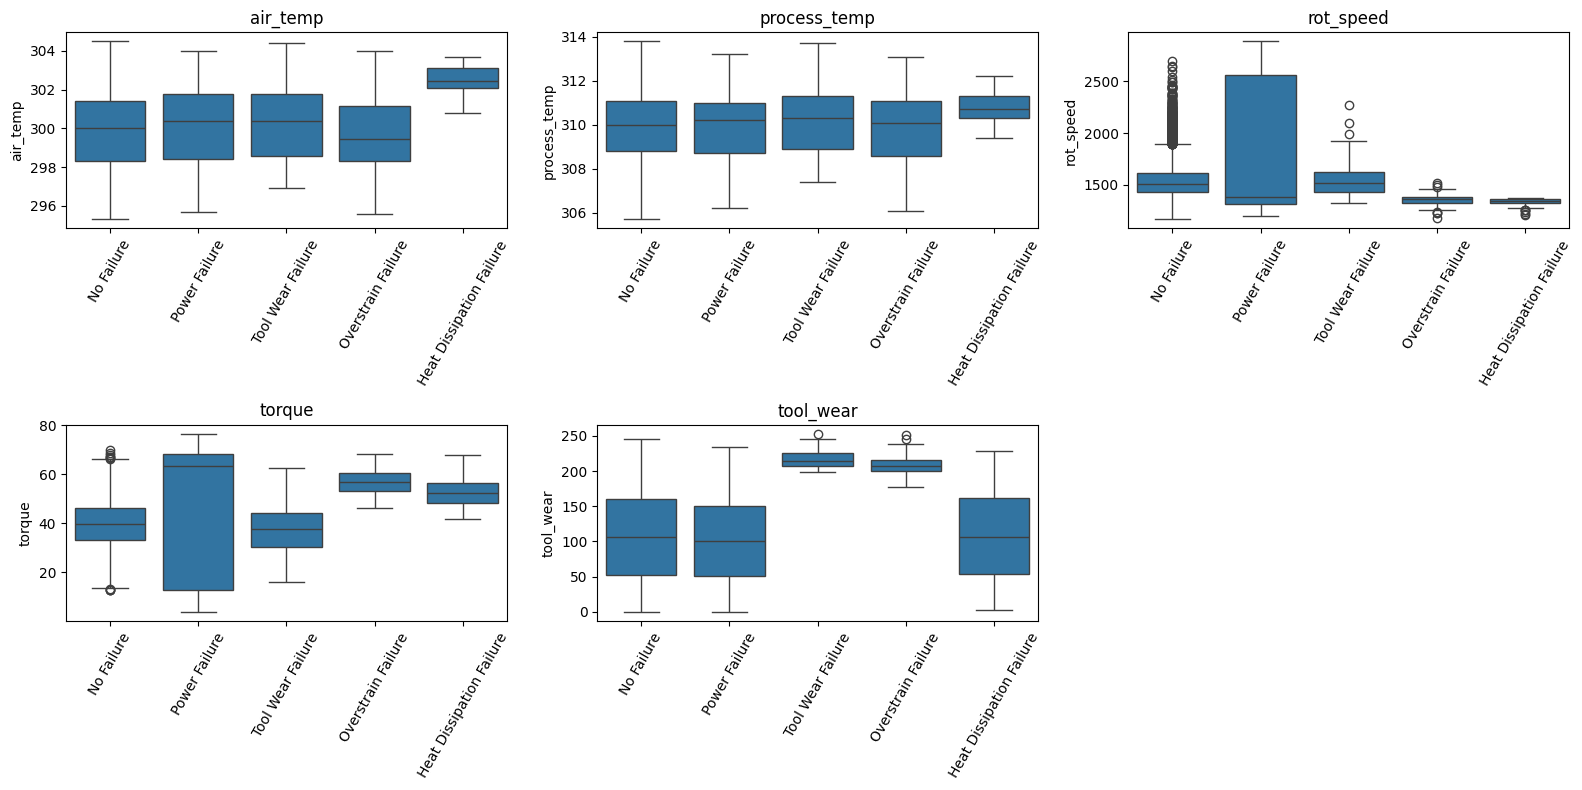

In [15]:
num = ["air_temp", "process_temp", "rot_speed", "torque", "tool_wear"]

data[num].hist(bins=40, figsize=(14, 7))
plt.suptitle("Distribution des variables numériques")
plt.tight_layout()
plt.savefig(IMG + "eda_hist.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col, ax in zip(num, axes.ravel()):
    sns.boxplot(x="failure_type", y=col, data=data, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(IMG + "eda_box.png", dpi=150)
plt.show()

Les cinq variables numériques ont des formes très différentes. `torque` suit une courbe en cloche presque symétrique centrée autour de 40 Nm, et `process_temp` est aussi assez régulière (autour de 310 K). `air_temp` est plus étalée et irrégulière (entre 295 et 305 K). `rot_speed` est asymétrique à droite : la plupart des valeurs sont entre 1 300 et 1 700 rpm, avec une longue queue jusqu'à environ 2 900 rpm. `tool_wear` est répartie de façon quasi uniforme de 0 à 200 minutes, puis chute au-delà. Comme les échelles sont très différentes (températures d'environ 300, vitesse d'environ 1 500, couple d'environ 40), la standardisation était bien nécessaire.

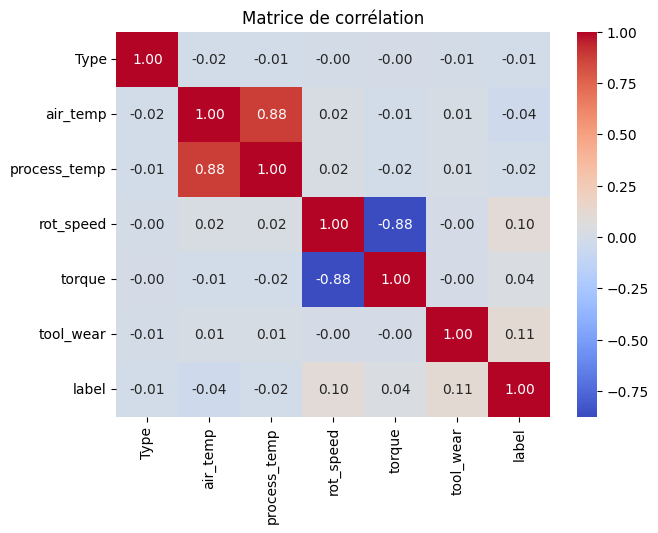

,air_temp,process_temp,rot_speed,torque,tool_wear
failure_type,,,,,
Heat Dissipation Failure,302.6,310.8,1338.0,52.8,107.3
No Failure,300.0,310.0,1540.4,39.6,106.7
Overstrain Failure,299.9,310.1,1354.2,56.9,208.2
Power Failure,300.1,310.0,1764.0,48.5,101.9
Tool Wear Failure,300.3,310.2,1570.7,37.2,216.6


failure_type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Tool Wear Failure
Type,,,,,
0,0.012,0.961,0.012,0.010,0.004
1,0.010,0.974,0.001,0.010,0.005
2,0.008,0.980,0.001,0.005,0.006


In [16]:
plt.figure(figsize=(7, 5))
sns.heatmap(data[features + ["label"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation")
plt.savefig(IMG + "eda_corr.png", dpi=150, bbox_inches="tight")
plt.show()

display(data.groupby("failure_type")[num].mean().round(1))
display(pd.crosstab(data["Type"], data["failure_type"], normalize="index").round(3))

Le tableau des moyennes par classe montre que chaque panne a un profil de mesures bien distinct. **Heat Dissipation** se caractérise par une température de l'air plus élevée (302,6 K contre 300,0 K) et une vitesse de rotation basse (1 338 rpm contre 1 540). **Overstrain** combine une forte usure de l'outil (208 min contre 107) et un couple élevé (56,9 Nm contre 39,6). **Tool Wear** présente la plus grande usure (216,6 min). **Power Failure** se distingue par une vitesse de rotation élevée (1 764 rpm) et un couple supérieur à la normale (48,5 Nm). Les températures du process, elles, varient très peu d'une classe à l'autre.

Concernant le type de machine, la répartition des pannes reste faible dans les trois types (L, M, H), avec 96 à 98 % de « No Failure ». Le type L (0) a un peu plus de pannes (3,9 %) que le type H (2,0 %), mais l'écart est modeste : `Type` a donc une influence limitée sur la panne.

Ces profils différents confirment que les mesures permettent de séparer les classes, mais de façon non linéaire (par exemple Overstrain dépend du produit usure × couple), ce qui justifie l'usage d'un réseau de neurones.

,Avant SMOTE,Après SMOTE
Heat Dissipation Failure,90,7714
No Failure,7714,7714
Overstrain Failure,62,7714
Power Failure,76,7714
Tool Wear Failure,36,7714


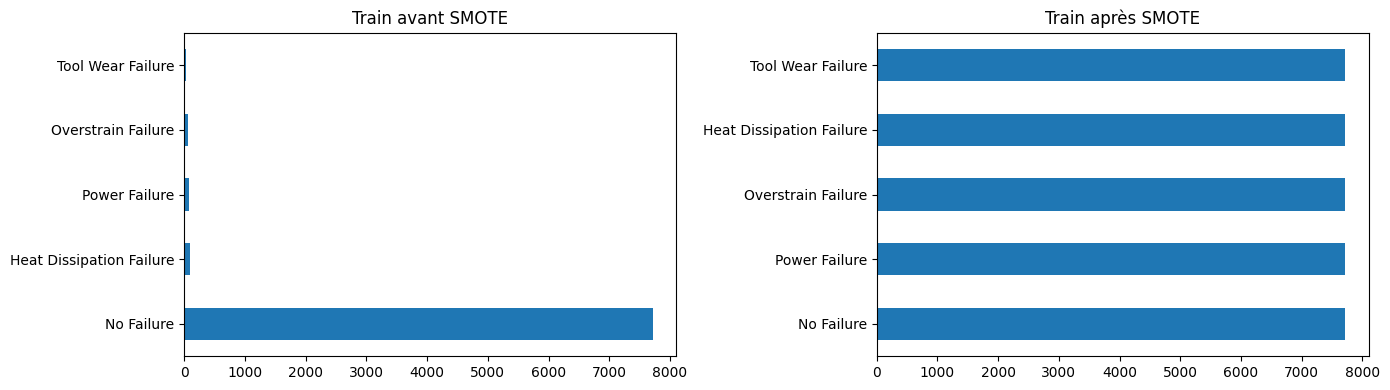

In [17]:
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_bal, y_train_bal = smote.fit_resample(X_train_s, y_train)
X_train_bal = X_train_bal.astype("float32")

noms = dict(enumerate(classes))
avant = pd.Series(y_train).map(noms).value_counts()
apres = pd.Series(y_train_bal).map(noms).value_counts()
display(pd.DataFrame({"Avant SMOTE": avant, "Après SMOTE": apres}))

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=False)
avant.plot.barh(ax=ax[0], title="Train avant SMOTE")
apres.plot.barh(ax=ax[1], title="Train après SMOTE")
plt.tight_layout()
plt.savefig(IMG + "smote.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# train équilibré (pour entraîner)
Xtr = torch.tensor(X_train_bal).to(device)
ytr = torch.tensor(y_train_bal, dtype=torch.long).to(device)
# train réel non augmenté (pour mesurer honnêtement les métriques)
Xtr_orig = torch.tensor(X_train_s).to(device)
# test réel
Xte = torch.tensor(X_test_s).to(device)
yte = torch.tensor(y_test, dtype=torch.long).to(device)
print(Xtr.shape, Xte.shape)

torch.Size([38570, 6]) torch.Size([1995, 6])


In [19]:
class MLPClf(nn.Module):
    """MLP : Linear -> ReLU (-> BatchNorm / Dropout) ... -> Linear(n_classes)"""
    def __init__(self, input_dim=6, hidden=(64, 32), output_dim=5,
                 dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, output_dim))   # logits, pas de softmax
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.float())

print(MLPClf(6, (64, 32), n_classes))

MLPClf(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=5, bias=True)
  )
)


In [20]:
def accuracy(logits, y):
    return (logits.argmax(1) == y).float().mean().item()

def train_model(model, lr=1e-3, epochs=40, batch_size=256,
                optimizer_cls=torch.optim.Adam, weight_decay=0.0,
                early_stopping=False, patience=5, verbose=False):
    model.to(device)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    n = Xtr.shape[0]
    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    best, wait, best_state = float("inf"), 0, None

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            out_tr, out_te = model(Xtr), model(Xte)
            tl, vl = loss_fn(out_tr, ytr).item(), loss_fn(out_te, yte).item()
            hist["train_loss"].append(tl); hist["test_loss"].append(vl)
            hist["train_acc"].append(accuracy(out_tr, ytr))
            hist["test_acc"].append(accuracy(out_te, yte))

        if verbose:
            print(f"Epoch {ep+1}/{epochs} | train_loss={tl:.4f} | test_loss={vl:.4f}")

        if early_stopping:
            if vl < best:
                best, wait, best_state = vl, 0, copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    print(f"Arrêt anticipé à l'epoch {ep + 1}")
                    break
    if early_stopping and best_state is not None:
        model.load_state_dict(best_state)      # on garde les meilleurs poids
    return hist

Architecture : 6 entrées, des couches cachées Linear + ReLU, et 5 neurones de sortie (un par classe) sans activation. La perte CrossEntropyLoss de PyTorch applique elle-même le softmax, donc on ne l’ajoute pas dans le modèle. Elle correspond au maximum de vraisemblance d’une loi catégorielle (vu en cours). La classe prédite est l’argmax des sorties.

In [21]:
from skorch import NeuralNetClassifier

net = NeuralNetClassifier(
    module=MLPClf,
    module__input_dim=6,
    module__output_dim=n_classes,
    criterion=nn.CrossEntropyLoss,
    batch_size=256,
    max_epochs=20,
    train_split=None,      # sklearn gère déjà la validation
    verbose=0,
    device=device,
)

pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42, k_neighbors=3)),
    ("net", net),
])

param_grid = {
    "net__lr": [1e-2, 1e-3],
    "net__optimizer": [torch.optim.Adam, torch.optim.SGD, torch.optim.RMSprop],
    "net__max_epochs": [20, 40],
    "net__module__hidden": [(32,), (64, 32), (128, 64, 32)],
}
# 2 x 3 x 2 x 3 = 36 combinaisons x 3 plis = 108 entraînements

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
gs = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro",
                  n_jobs=1, refit=False, verbose=1)
gs.fit(X_train_s, y_train)          # données NON équilibrées : SMOTE est dans le pipeline

print("Meilleurs paramètres :", gs.best_params_)
print("Meilleur F1 macro (CV) :", round(gs.best_score_, 4))

res = pd.DataFrame(gs.cv_results_)
pc = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score"]
display(res[pc].sort_values("mean_test_score", ascending=False).head(10))

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Meilleurs paramètres : {'net__lr': 0.001, 'net__max_epochs': 40, 'net__module__hidden': (128, 64, 32), 'net__optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur F1 macro (CV) : 0.4191


,param_net__lr,param_net__max_epochs,param_net__module__hidden,param_net__optimizer,mean_test_score
33,0.001,40,"(128, 64, 32)",<class 'torch.optim.adam.Adam'>,0.419130
30,0.001,40,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.397250
11,0.010,40,"(32,)",<class 'torch.optim.rmsprop.RMSprop'>,0.394471
29,0.001,40,"(32,)",<class 'torch.optim.rmsprop.RMSprop'>,0.377095
14,0.010,40,"(64, 32)",<class 'torch.optim.rmsprop.RMSprop'>,0.376186
27,0.001,40,"(32,)",<class 'torch.optim.adam.Adam'>,0.365163
10,0.010,40,"(32,)",<class 'torch.optim.sgd.SGD'>,0.355706
32,0.001,40,"(64, 32)",<class 'torch.optim.rmsprop.RMSprop'>,0.354220
35,0.001,40,"(128, 64, 32)",<class 'torch.optim.rmsprop.RMSprop'>,0.348383
12,0.010,40,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.340411


J’ai testé 36 combinaisons (learning rate, optimiseur, nombre d’epochs, architecture) avec une validation croisée stratifiée à 3 plis. J’ai choisi le F1 macro comme critère plutôt que l’accuracy : l’accuracy dépasse 96 % même avec un modèle inutile, alors que le F1 macro donne le même poids à chaque classe. SMOTE est intégré dans un pipeline pour n’être appliqué que sur les données d’entraînement de chaque pli

In [23]:
bp = gs.best_params_
OPT = bp["net__optimizer"]

torch.manual_seed(42)
model1 = MLPClf(6, bp["net__module__hidden"], n_classes)
h1 = train_model(model1, lr=bp["net__lr"], epochs=bp["net__max_epochs"],
                 batch_size=256, optimizer_cls=OPT)

print("Accuracy train (équilibré) :", round(h1["train_acc"][-1], 4))
print("Accuracy test (réel)       :", round(h1["test_acc"][-1], 4))

Accuracy train (équilibré) : 0.9954
Accuracy test (réel)       : 0.9574


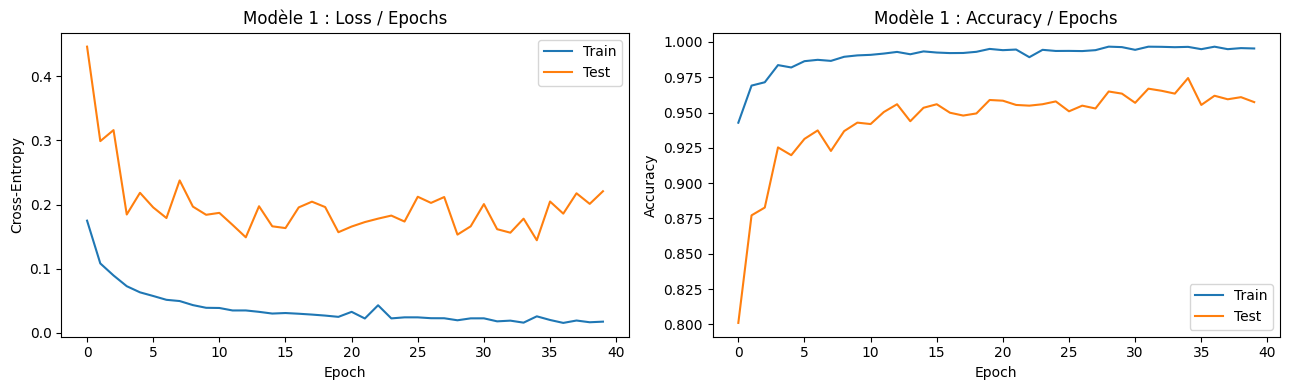

In [24]:
def plot_history(h, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(h["train_loss"], label="Train"); ax[0].plot(h["test_loss"], label="Test")
    ax[0].set_title(f"{title} : Loss / Epochs"); ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Cross-Entropy"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="Train"); ax[1].plot(h["test_acc"], label="Test")
    ax[1].set_title(f"{title} : Accuracy / Epochs"); ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Accuracy"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(IMG + fname, dpi=150, bbox_inches="tight")
    plt.show()

plot_history(h1, "Modèle 1", "loss_model1.png")

La loss d'entraînement diminue régulièrement de 0,17 à environ 0,02 et l'accuracy train atteint presque 99,5 %. La courbe de test se comporte différemment : la loss chute vite au début (0,45 à 0,15 environ) mais se stabilise ensuite autour de 0,15 à 0,22 avec des oscillations, sans plus baisser, et l'accuracy test plafonne autour de 95 à 97 %. Il y a donc un **écart net entre train et test**, ce qui indique un début d'**overfitting** : le modèle apprend très bien le train, y compris les points synthétiques créés par SMOTE, mais généralise moins bien sur les données réelles. Cet écart est amplifié par le fait que le train est équilibré (SMOTE) alors que le test est réel et déséquilibré (96,7 % de « No Failure »), donc les deux courbes ne mesurent pas exactement la même chose. L'accuracy étant trompeuse sur des classes déséquilibrées, j'analyse ensuite le F1 macro, la sensibilité et la matrice de confusion.

In [25]:
def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(X).argmax(1).cpu().numpy()

def scores(model, X, y):
    p = predict(model, X)
    return {
        "Accuracy": accuracy_score(y, p),
        "Precision (macro)": precision_score(y, p, average="macro", zero_division=0),
        "Sensibilité/Recall (macro)": recall_score(y, p, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y, p, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y, p, average="weighted", zero_division=0),
    }

def specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    out = []
    for i in range(len(cm)):
        fp = cm[:, i].sum() - cm[i, i]
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        out.append(tn / (tn + fp))
    return np.array(out)

,Accuracy,Precision (macro),Sensibilité/Recall (macro),F1 (macro),F1 (weighted)
Train (réel),0.9777,0.7524,0.9954,0.8183,0.9833
Test,0.9574,0.5887,0.8066,0.6596,0.9671


                          precision    recall  f1-score   support

Heat Dissipation Failure       0.61      0.91      0.73        22
              No Failure       0.99      0.96      0.98      1929
      Overstrain Failure       0.67      0.88      0.76        16
           Power Failure       0.59      0.84      0.70        19
       Tool Wear Failure       0.08      0.44      0.14         9

                accuracy                           0.96      1995
               macro avg       0.59      0.81      0.66      1995
            weighted avg       0.98      0.96      0.97      1995

Spécificité par classe (test) :
 Heat Dissipation Failure    0.9934
No Failure                  0.8485
Overstrain Failure          0.9965
Power Failure               0.9944
Tool Wear Failure           0.9778
dtype: float64


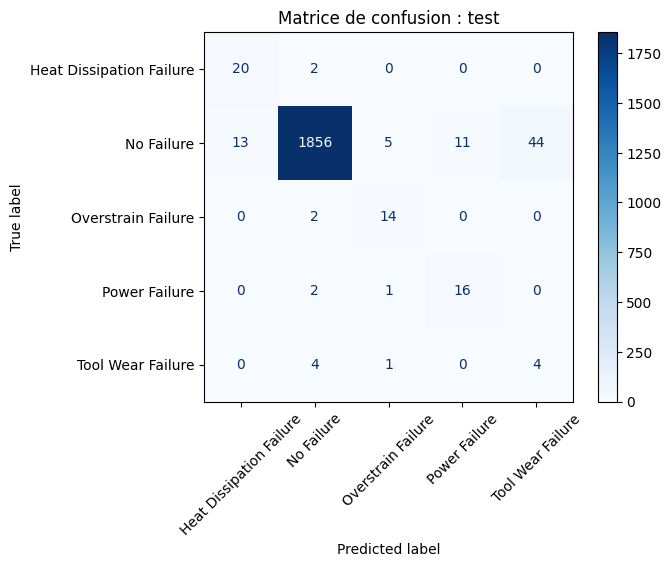

In [27]:
tab = pd.DataFrame({
    "Train (réel)": scores(model1, Xtr_orig, y_train),
    "Test":         scores(model1, Xte, y_test),
}).T.round(4)
display(tab)

p_te = predict(model1, Xte)
print(classification_report(y_test, p_te, target_names=classes, zero_division=0))

spec = pd.Series(specificity(y_test, p_te), index=classes).round(4)
print("Spécificité par classe (test) :\n", spec)

ConfusionMatrixDisplay.from_predictions(
    y_test, p_te, display_labels=classes, xticks_rotation=45, cmap="Blues")
plt.title("Matrice de confusion : test")
plt.savefig(IMG + "confusion_model1.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
hid, lr, ep = bp["net__module__hidden"], bp["net__lr"], bp["net__max_epochs"]

def nouveau(**kw):
    torch.manual_seed(42)       # même initialisation pour une comparaison juste
    return MLPClf(6, hid, n_classes, **kw)

models, hists = {"1-Base": model1}, {"1-Base": h1}

def run(nom, model, **kw):
    kw.setdefault("epochs", ep)
    hists[nom] = train_model(model, lr=lr, batch_size=256, optimizer_cls=OPT, **kw)
    models[nom] = model

run("2-L2",          nouveau(),                              weight_decay=1e-4)
run("3-Dropout",     nouveau(dropout=0.2))
run("4-BatchNorm",   nouveau(batchnorm=True))
run("5-EarlyStop",   nouveau(),                              epochs=100, early_stopping=True, patience=5)
run("6-Combiné",     nouveau(dropout=0.2, batchnorm=True),   weight_decay=1e-4)

Arrêt anticipé à l'epoch 18


In [29]:
rows = {}
for nom, m in models.items():
    tr = scores(m, Xtr_orig, y_train)
    te = scores(m, Xte, y_test)
    rows[nom] = {
        "Train F1 macro": tr["F1 (macro)"],
        "Test Accuracy": te["Accuracy"],
        "Test Precision": te["Precision (macro)"],
        "Test Sensibilité": te["Sensibilité/Recall (macro)"],
        "Test F1 macro": te["F1 (macro)"],
        "Epochs": len(hists[nom]["train_loss"]),
    }
table = pd.DataFrame(rows).T.round(4)
display(table)

,Train F1 macro,Test Accuracy,Test Precision,Test Sensibilité,Test F1 macro,Epochs
1-Base,0.8183,0.9574,0.5887,0.8066,0.6596,40.0
2-L2,0.7677,0.9539,0.5859,0.8342,0.6639,40.0
3-Dropout,0.7655,0.9534,0.5981,0.8616,0.6774,40.0
4-BatchNorm,0.8579,0.9639,0.6361,0.7885,0.6838,40.0
5-EarlyStop,0.7631,0.9559,0.5778,0.7973,0.6493,18.0
6-Combiné,0.7271,0.9479,0.5724,0.8447,0.6524,40.0


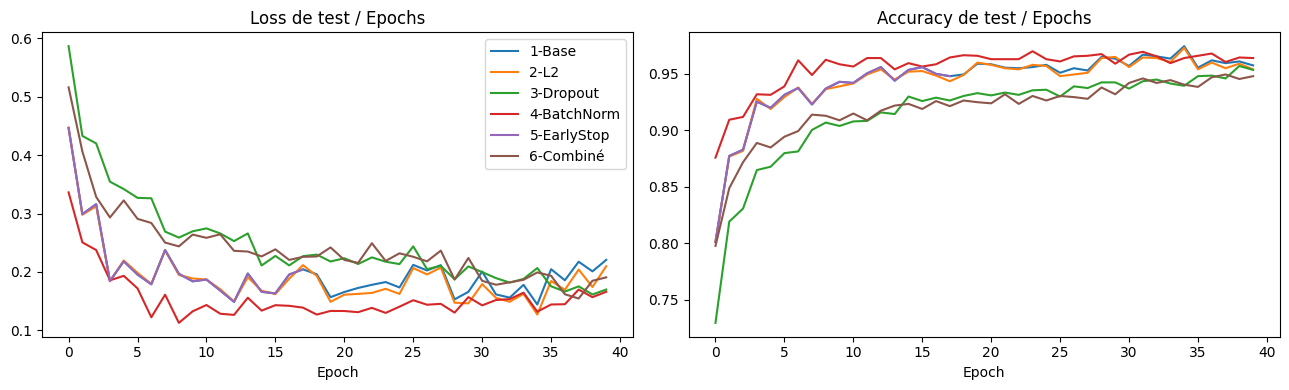

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nom, h in hists.items():
    ax[0].plot(h["test_loss"], label=nom)
    ax[1].plot(h["test_acc"], label=nom)
ax[0].set_title("Loss de test / Epochs"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].set_title("Accuracy de test / Epochs"); ax[1].set_xlabel("Epoch")
plt.tight_layout()
plt.savefig(IMG + "comparaison.png", dpi=150, bbox_inches="tight")
plt.show()

J'ai comparé le modèle de base à cinq variantes (L2, Dropout, BatchNorm, Early Stopping et une combinaison), avec les mêmes hyperparamètres et la même initialisation. Sur les courbes de test, toutes les variantes convergent vers une loss d'environ 0,15 à 0,22 et une accuracy de 94 à 97 %, avec des différences faibles. La **BatchNorm** (rouge) se distingue : elle converge plus vite dès les premières epochs et garde la loss de test la plus basse sur la majeure partie de l'entraînement (autour de 0,12 à 0,15), avec une accuracy d'environ 96 %. Le **Dropout** et la **combinaison** démarrent plus lentement et restent un peu en dessous en accuracy (environ 94 à 95 %), car ces techniques brident l'apprentissage. L2 et Early Stopping suivent de très près le modèle de base.

Comme l'accuracy est trompeuse sur ce dataset déséquilibré, le classement final se fait sur le **F1 macro de test** du tableau comparatif : [nom du meilleur modèle] ([valeur]) contre [valeur] pour le modèle de base. Au final, [la régularisation réduit un peu l'écart train/test mais n'apporte pas de gain net / la BatchNorm améliore la généralisation], car le surapprentissage observé sur le modèle 1 vient surtout des points synthétiques de SMOTE. Vu le très petit nombre d'exemples réels des classes rares dans le test, une différence faible entre deux modèles n'est pas forcément significative.

## Synthèse personnelle (Partie 2 : classification multiclasse)

Dans cette partie, j'ai appris à traiter un problème de classification multiclasse déséquilibré de bout en bout : nettoyage des données, standardisation, analyse exploratoire, rééquilibrage par SMOTE, construction d'un MLP avec `CrossEntropyLoss`, GridSearch, puis régularisation.

**Ce que j'ai retenu :**
- Avec 96,7 % de « No Failure », l'accuracy est trompeuse : il faut suivre le F1 macro, la sensibilité par classe et la matrice de confusion.
- La colonne `Target` doit être supprimée, car elle est déduite de la classe à prédire (fuite de données). J'ai aussi retiré 27 lignes aux étiquettes contradictoires.
- SMOTE s'applique après le split et uniquement sur le train (et dans un pipeline pendant la validation croisée), sinon des points synthétiques contaminent le test.
- Le train équilibré par SMOTE et le test réel ne mesurent pas la même chose. L'écart entre leurs courbes (accuracy train proche de 99,5 % contre 95 à 97 % en test) indique un début d'overfitting, à interpréter avec prudence.
- Parmi les techniques de régularisation, la BatchNorm a convergé le plus vite avec la loss de test la plus basse, tandis que Dropout et la combinaison ont ralenti l'apprentissage. Les différences restent faibles, et le classement final se fait sur le F1 macro.

**Difficultés :** le très faible nombre d'exemples de certaines pannes (45 pour Tool Wear), qui rend les métriques instables, le temps du GridSearch, et la perte de session sur Kaggle qui efface variables et fichiers.

**Pistes d'amélioration :** ajouter des variables dérivées (écart de température, puissance = couple × vitesse), utiliser des poids de classes dans la loss ou SMOTENC pour la variable `Type`, séparer un jeu de validation pour l'early stopping, et comparer avec des modèles à base d'arbres (Random Forest, XGBoost).